In [1]:
import os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import ternary

In [29]:
import os
import numpy as np
import networkx as nx

base_path = "/home/ylx/project/SC_FC/BWM/result/wo_layer/stage2/tuning"
results = []

for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)
    if not os.path.isdir(folder_path):
        continue
    
    try:
        bs = int(folder.split("_")[0].replace("bs", ""))
        dp = float(folder.split("_")[1].replace("dp", ""))
        sw = float(folder.split("_")[2].replace("sw", ""))
    except Exception:
        continue
    
    npy_path = os.path.join(folder_path, "dynamic_full_graphs.npy")
    if not os.path.exists(npy_path):
        continue

    data = np.load(npy_path, allow_pickle=True)
    mean_graph = np.mean(data, axis=0)
    avg_centrality = []
    matrices = []

    for g in data:
        if isinstance(g, np.ndarray):
            adj = g.copy()
        elif isinstance(g, (nx.Graph, nx.DiGraph)):
            adj = nx.to_numpy_array(g)
        elif isinstance(g, dict) and "adj" in g:
            adj = g["adj"].copy()
        else:
            continue

        matrices.append(adj)
        
        N = adj.shape[0]
        if N <= 1:
            avg_centrality.append(0.0)
            continue
            
        np.fill_diagonal(adj, 0)
        
        out_strengths = np.sum(adj, axis=1)
        
        centrality_val = np.mean(out_strengths) / (N - 1)
        avg_centrality.append(centrality_val)
    
    if len(matrices) == 0:
        continue

    mean_centrality = np.mean(avg_centrality)

    train_loss_path = os.path.join(folder_path, "train_losses.npy")
    if os.path.exists(train_loss_path):
        train_losses = np.load(train_loss_path, allow_pickle=True)
        num_epochs = len(train_losses)
    else:
        num_epochs = np.nan

    avg_graph = np.mean(matrices, axis=0)
    num_pos = np.sum(avg_graph > 0)
    num_neg = np.sum(avg_graph < 0)
    pos_neg_ratio = np.inf if num_neg == 0 else num_pos / num_neg

    val_loss_path = os.path.join(folder_path, "val_losses.npy")
    if os.path.exists(val_loss_path):
        val_losses = np.load(val_loss_path, allow_pickle=True)
        if len(val_losses) > 0:
            best_val_loss = np.nanmin(val_losses)
        else:
            best_val_loss = np.nan
    else:
        best_val_loss = np.nan

    results.append((bs, dp, sw, mean_centrality, num_epochs, pos_neg_ratio, mean_graph, best_val_loss))

results = np.array(results, dtype=object)

print(f"Statistics complete, a total of {len(results)} parameter combinations were calculated.")
print("Data Structure: [bs, dp, sw, mean_out_degree_centrality, num_epochs, pos_neg_ratio, mean_graph, best_val_loss]")

Statistics complete, a total of 64 parameter combinations were calculated.
Data Structure: [bs, dp, sw, mean_out_degree_centrality, num_epochs, pos_neg_ratio, mean_graph, best_val_loss]


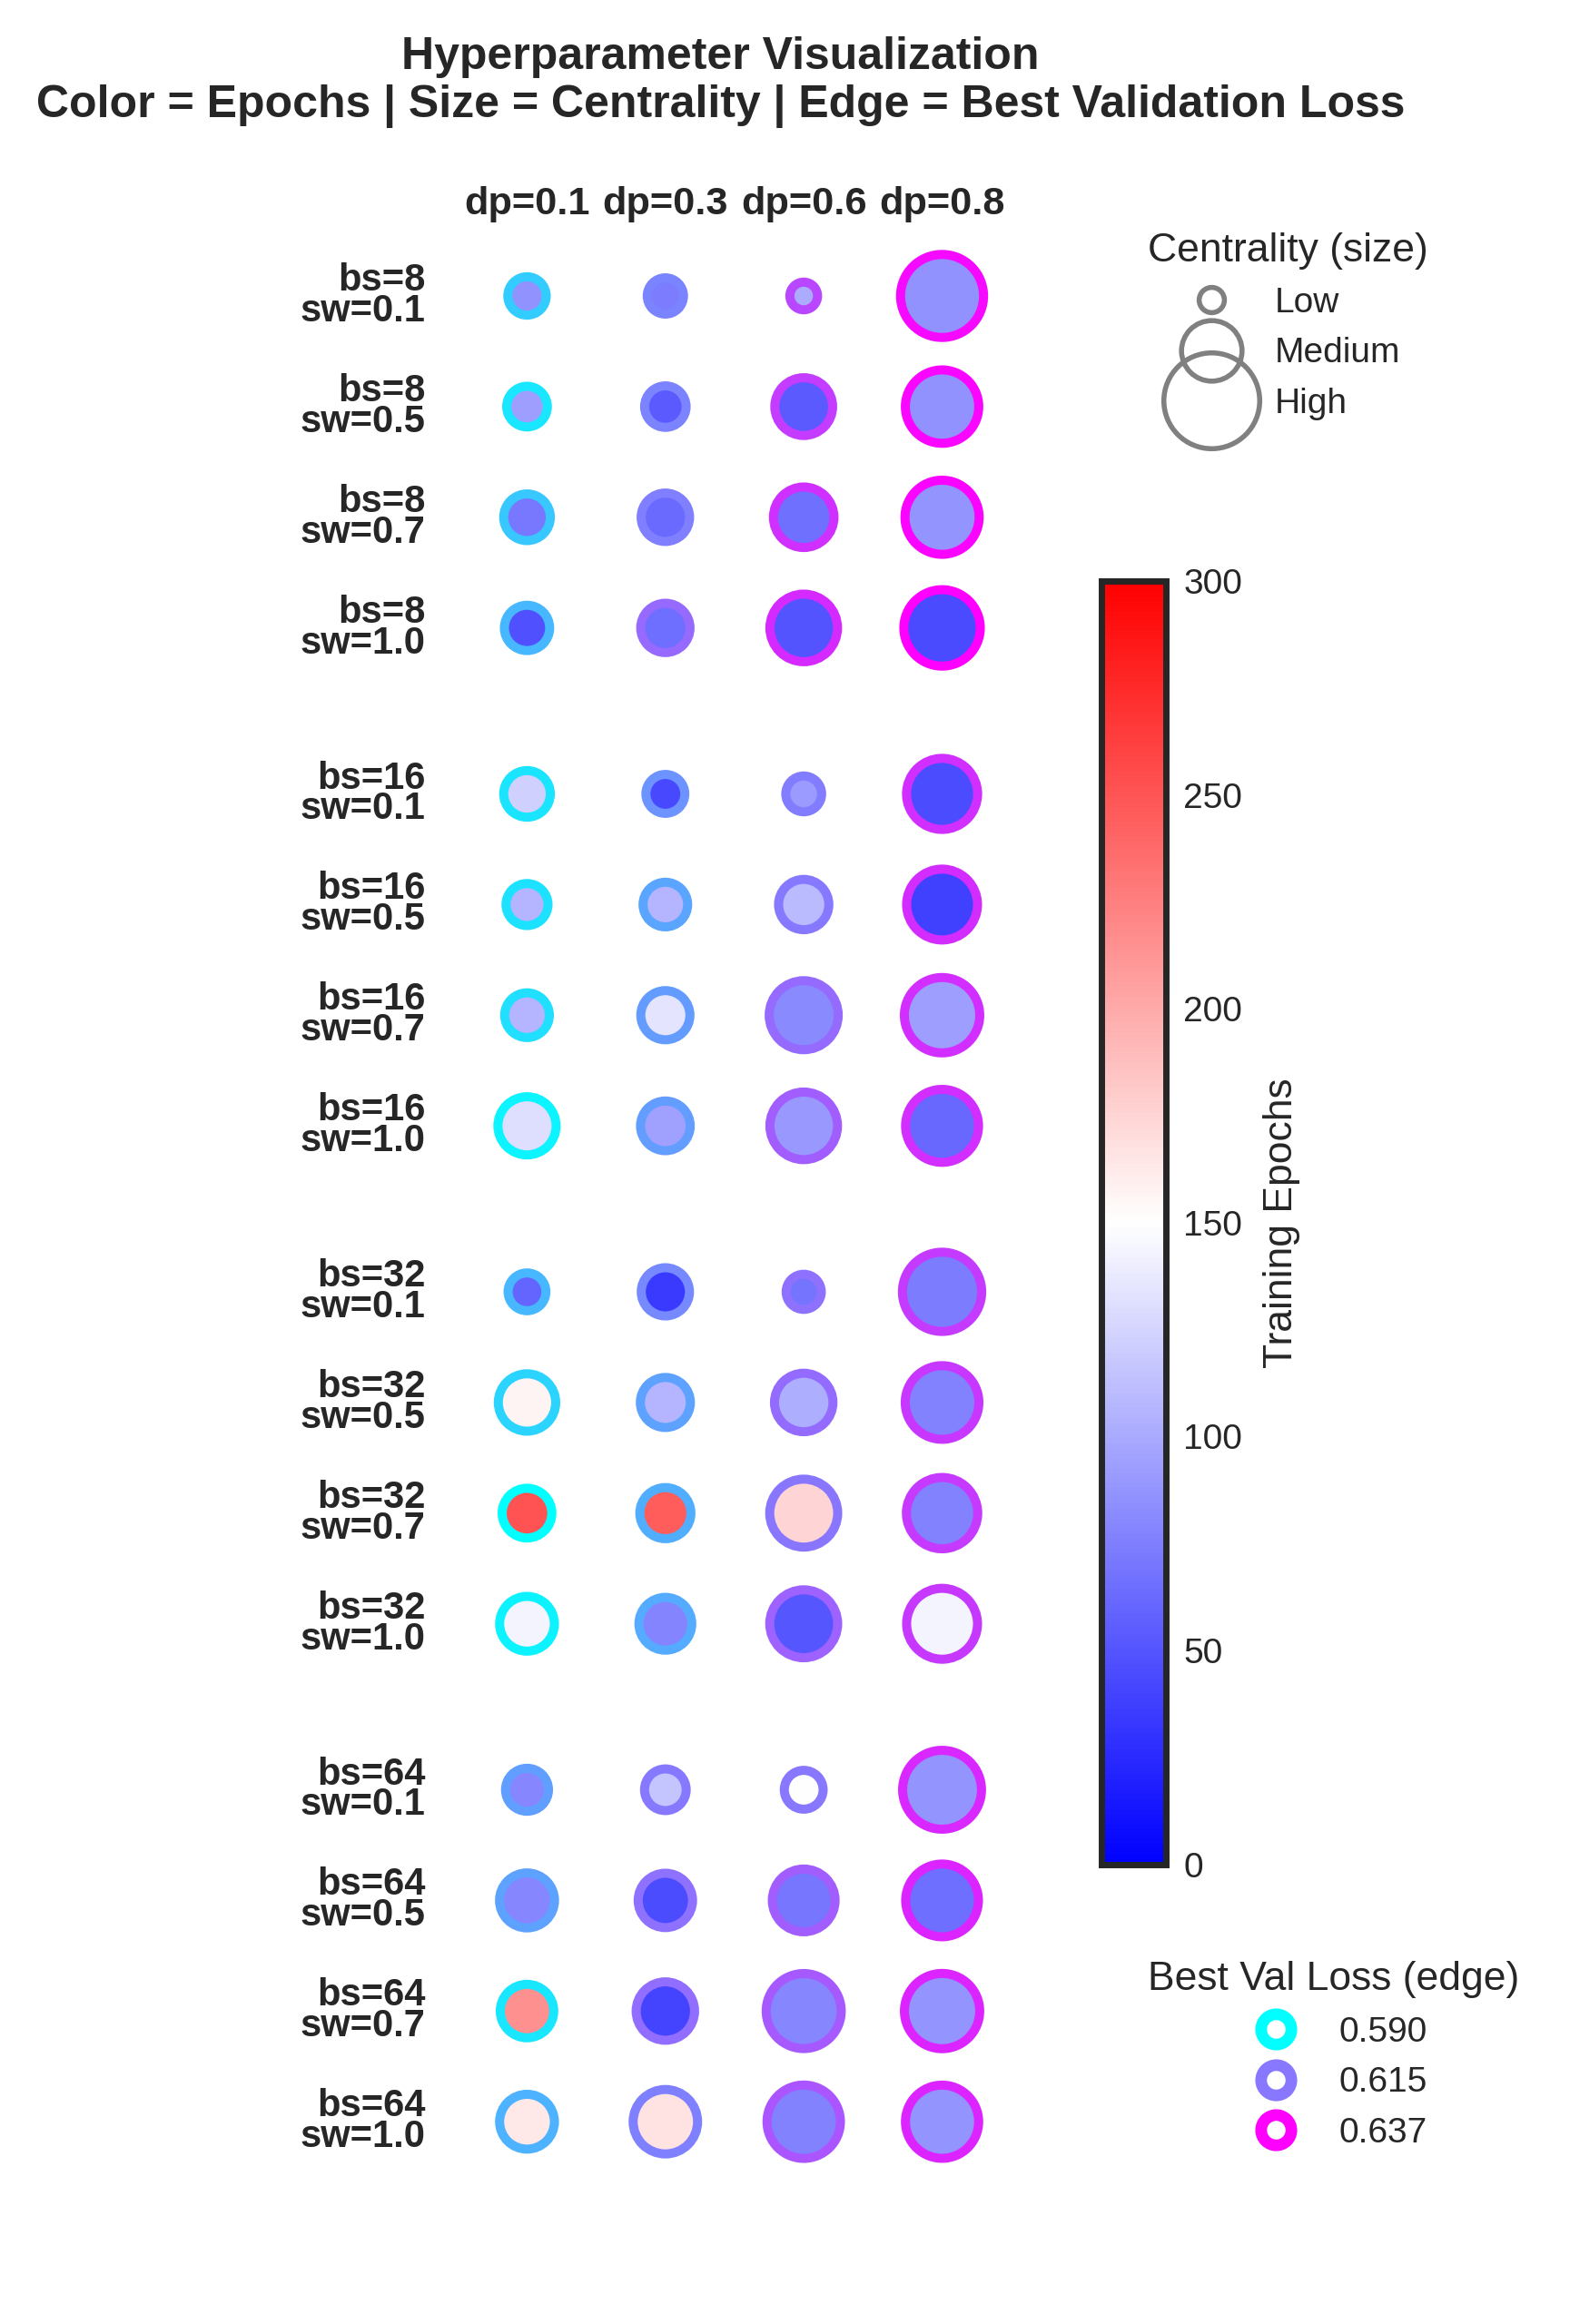

In [17]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.lines import Line2D

records = np.array(results, dtype=object)


bs_values = [8, 16, 32, 64]
dp_values = [0.1, 0.3, 0.6, 0.8]
sw_values = [0.1, 0.5, 0.7, 1.0]


order = []
for bs in bs_values:
    for sw in sw_values:
        for dp in dp_values:
            subset = records[(records[:,0]==bs)&(records[:,1]==dp)&(records[:,2]==sw)]
            if len(subset) > 0:
                order.append(subset[0])
records_ordered = np.array(order)


centrality = records_ordered[:, 3]
epochs = records_ordered[:, 4]
best_val_loss = records_ordered[:, 7]


norm_epochs = mpl.colors.Normalize(vmin=0, vmax=300)
cmap_fill = plt.cm.bwr  
norm_loss = mpl.colors.Normalize(vmin=np.nanmin(best_val_loss), vmax=np.nanmax(best_val_loss))
cmap_edge = plt.cm.cool 

edge_colors = [cmap_edge(norm_loss(v)) for v in best_val_loss]


min_r, max_r = 0.15, 0.45
radii = min_r + (max_r - min_r) * (centrality - np.min(centrality)) / (np.max(centrality) - np.min(centrality))


spacing_x = 1.5
spacing_y = 1.2
extra_gap = 0.6

x_coords, y_coords = [], []
current_y = 0
for bs in bs_values:
    for sw in sw_values:
        for dp_i, dp in enumerate(dp_values):
            x_coords.append(dp_i * spacing_x)
            y_coords.append(-current_y)
        current_y += spacing_y
    current_y += extra_gap

x_coords = np.array(x_coords)
y_coords = np.array(y_coords)


plt.style.use("seaborn-v0_8-white")
fig, ax = plt.subplots(figsize=(7.2, 6.5), dpi=400)

for i in range(len(records_ordered)):
    fill_color = cmap_fill(norm_epochs(epochs[i]))
    edge_color = edge_colors[i]
    circle = plt.Circle((x_coords[i], y_coords[i]), radii[i],
                        facecolor=fill_color, edgecolor=edge_color, lw=1.8)
    ax.add_patch(circle)

group_offsets = np.arange(len(bs_values)) * (len(sw_values)*spacing_y + extra_gap)
for g, bs in enumerate(bs_values):
    for j, sw in enumerate(sw_values):
        ax.text(-1.1, -(group_offsets[g] + j*spacing_y), f"bs={int(bs)}\nsw={sw:.1f}",
                ha='right', va='center', fontsize=7.5, weight='bold', linespacing=0.8)

for j, dp in enumerate(dp_values):
    ax.text(j*spacing_x, 0.8, f"dp={dp:.1f}", ha='center', va='bottom', fontsize=7.8, weight='bold')


ax.set_xlim(-1.8, len(dp_values)*spacing_x)
ax.set_ylim(-current_y, 1.5)
ax.set_aspect('equal')
ax.axis('off')


sm = plt.cm.ScalarMappable(cmap=cmap_fill, norm=norm_epochs)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.01)
cbar.set_label("Training Epochs", fontsize=8)
cbar.ax.tick_params(labelsize=7)


size_levels = [np.min(centrality), (np.min(centrality)+np.max(centrality))/2, np.max(centrality)]
size_labels = ["Low", "Medium", "High"]
size_handles = [
    Line2D([], [], marker='o', color='gray', linestyle='None',
           markersize=5 + 14*(r - np.min(centrality))/(np.max(centrality)-np.min(centrality)),
           markerfacecolor='none', label=label)
    for r, label in zip(size_levels, size_labels)
]

loss_levels = [np.nanmin(best_val_loss), np.nanmedian(best_val_loss), np.nanmax(best_val_loss)]
loss_handles = [
    Line2D([], [], marker='o', linestyle='None', markerfacecolor='none',
           markeredgewidth=2.3, markeredgecolor=cmap_edge(norm_loss(v)),
           label=f"{v:.3f}") for v in loss_levels
]

legend1 = ax.legend(handles=size_handles, title="Centrality (size)",
                    loc='upper left', bbox_to_anchor=(1.05, 0.98),
                    fontsize=7, title_fontsize=8, frameon=False)
legend2 = ax.legend(handles=loss_handles, title="Best Val Loss (edge)",
                    loc='lower left', bbox_to_anchor=(1.05, 0.05),
                    fontsize=7, title_fontsize=8, frameon=False)
ax.add_artist(legend1)


plt.title("Hyperparameter Visualization\nColor = Epochs | Size = Centrality | Edge = Best Validation Loss",
          fontsize=9, pad=8, weight='bold')

plt.tight_layout()

plt.savefig("hyperparam_visual_w_layer_stage3.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()


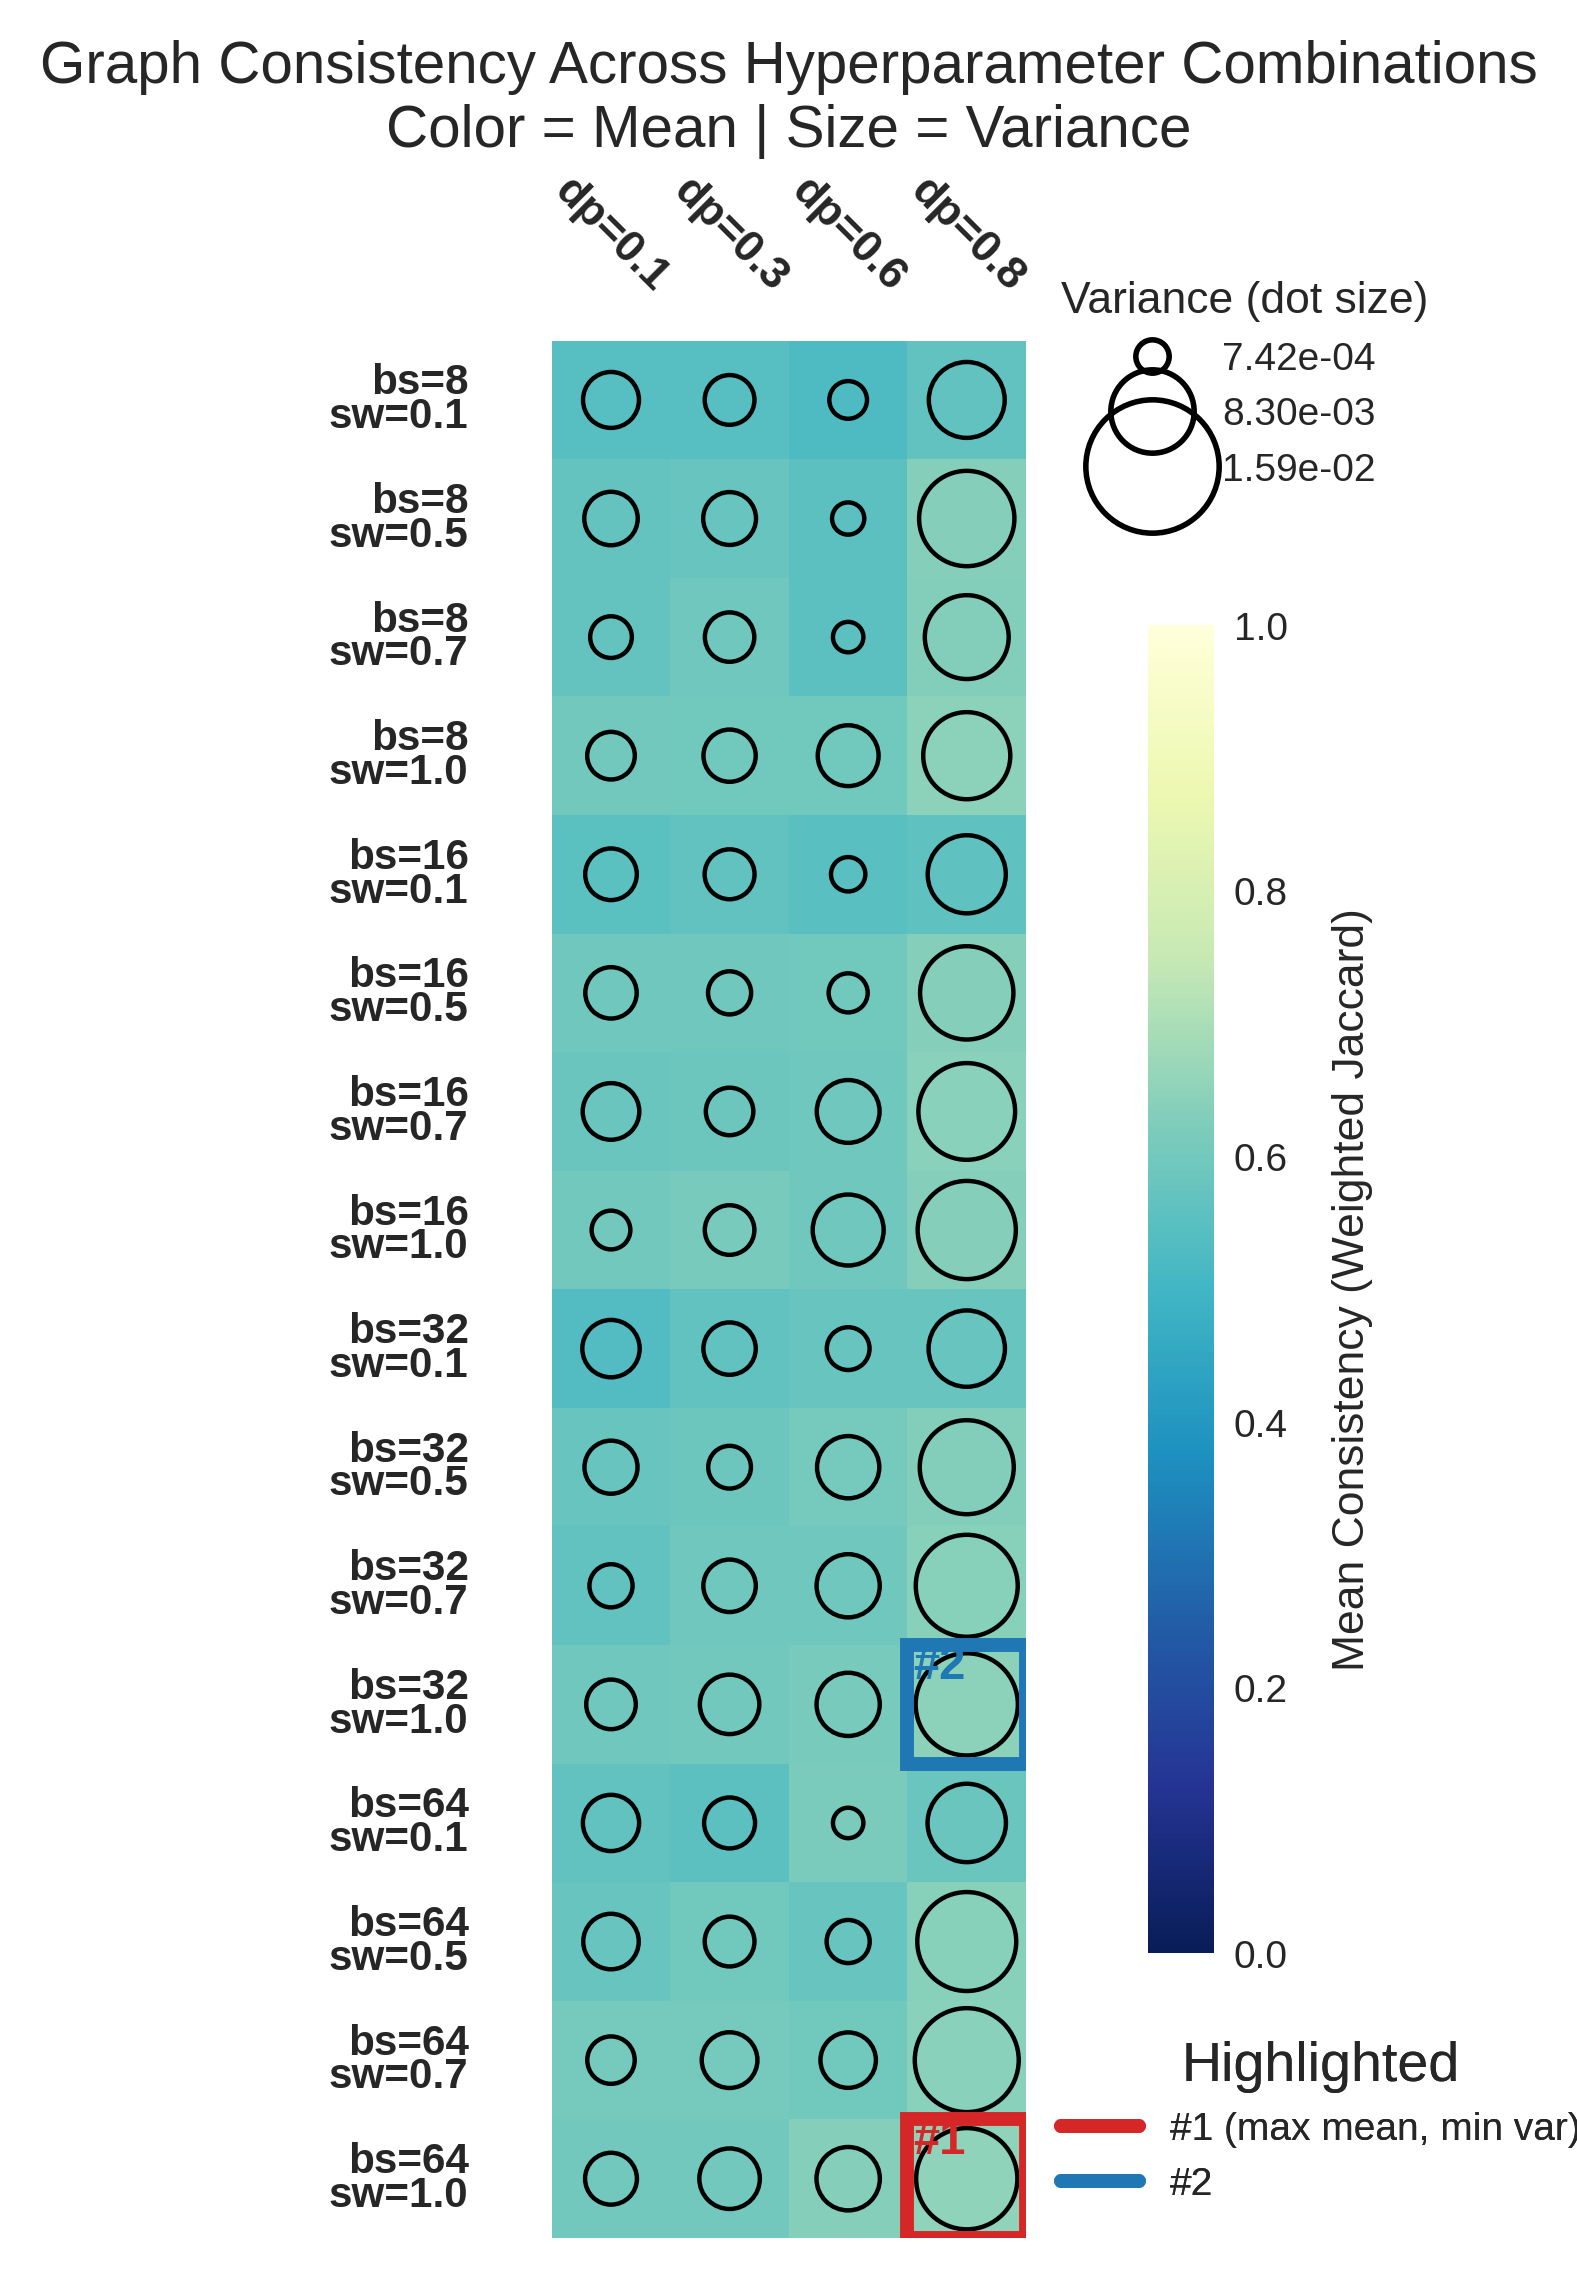

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
import matplotlib.patches as patches

# === 数据准备 ===
records = np.array(results, dtype=object)
bs_values = [8, 16, 32, 64]
dp_values = [0.1, 0.3, 0.6, 0.8]
sw_values = [0.1, 0.5, 0.7, 1.0]

# === 排列顺序 ===
ordered = []
for bs in bs_values:
    for sw in sw_values:
        for dp in dp_values:
            subset = records[(records[:, 0] == bs) & (records[:, 1] == dp) & (records[:, 2] == sw)]
            if len(subset) > 0:
                ordered.append(subset[0])
ordered = np.array(ordered, dtype=object)

avg_graphs = ordered[:, 6]  # (64, N, N)

# === 一致性函数 ===
def weighted_jaccard(A, B, threshold=0.01):
    A = np.nan_to_num(A)
    B = np.nan_to_num(B)

    A, B = A.copy(), B.copy()

    np.fill_diagonal(A, 0)
    np.fill_diagonal(B, 0)

    Ap = np.where(A > threshold, A, 0)
    Bp = np.where(B > threshold, B, 0)

    An = np.where(A < -threshold, -A, 0)
    Bn = np.where(B < -threshold, -B, 0)

    num_pos = np.sum(np.minimum(Ap, Bp))
    den_pos = np.sum(np.maximum(Ap, Bp))

    num_neg = np.sum(np.minimum(An, Bn))
    den_neg = np.sum(np.maximum(An, Bn))

    J_pos = 0 if den_pos == 0 else num_pos / den_pos
    J_neg = 0 if den_neg == 0 else num_neg / den_neg

    return 0.5 * (J_pos + J_neg)

n = len(avg_graphs)

S = np.zeros((n, n))
for i in range(n):
    for j in range(i, n):
        v = weighted_jaccard(avg_graphs[i], avg_graphs[j])
        S[i, j] = S[j, i] = v

# === 每个组合与其他组合的一致性均值 & 方差 ===
means = np.mean(np.where(np.eye(n, dtype=bool), np.nan, S), axis=1, where=~np.eye(n, dtype=bool))
vars_ = np.var(np.where(np.eye(n, dtype=bool), np.nan, S), axis=1, where=~np.eye(n, dtype=bool))

# === 转换为矩阵形状（行 = bs×sw，列 = dp）===
H_mean = means.reshape(len(bs_values) * len(sw_values), len(dp_values))
H_var = vars_.reshape(len(bs_values) * len(sw_values), len(dp_values))

# === 绘图 ===
plt.style.use("seaborn-v0_8-white")

# === 改进：横向更宽（7.2 → 8.6），给标签与色条留足空间 ===
fig, ax = plt.subplots(figsize=(8.6, 6.3), dpi=400)

# === 主热图 ===
sns.heatmap(
    H_mean,
    cmap="YlGnBu_r",
    vmin=0, vmax=1,
    square=True,
    cbar_kws={"label": "Mean Consistency (Weighted Jaccard)", "shrink": 0.7, "pad": 0.04},
    ax=ax
)

# === 调整 colorbar 位置与字体 ===
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=7)
cbar.set_label("Mean Consistency (Weighted Jaccard)", fontsize=8, labelpad=8)

# === 方差 → 圆圈大小 ===
vmin, vmax = np.min(H_var), np.max(H_var)
s_min, s_max = 30, 350
sizes = s_min + (H_var - vmin) / (vmax - vmin + 1e-9) * (s_max - s_min)

for i in range(H_var.shape[0]):
    for j in range(H_var.shape[1]):
        ax.scatter(j + 0.5, i + 0.5, s=sizes[i, j],
                   facecolors='none', edgecolors='k', linewidths=0.8)

# === 左侧 (bs, sw) 标签 ===
spacing_y = 1.0
extra_gap = 0.2
group_offsets = np.arange(len(bs_values)) * (len(sw_values) * spacing_y + extra_gap)

for g, bs in enumerate(bs_values):
    for j, sw in enumerate(sw_values):
        idx = g * len(sw_values) + j
        ax.text(-0.7, idx + 0.5,
                f"bs={int(bs)}\nsw={sw:.1f}",
                ha='right', va='center',
                fontsize=7.6, weight='bold', linespacing=0.8)

# === 顶部 dp 标签 ===
# ↓ 调整：更靠上、增加间距，防止 overlap
for j, dp in enumerate(dp_values):
    ax.text(j + 0.5, -0.35, f"dp={dp:.1f}",
            ha='center', va='bottom',
            fontsize=8, weight='bold', rotation=-45)

# === 方差图例（右移 + 垂直居中） ===
var_levels = np.linspace(vmin, vmax, 3)
size_handles = [
    Line2D([], [], marker='o', linestyle='None',
           markerfacecolor='none', markeredgecolor='k', markeredgewidth=1,
           markersize=6 + 18 * (v - vmin) / (vmax - vmin + 1e-9),
           label=f"{v:.2e}")  # ← 科学计数法显示
    for v in var_levels
]
legend2 = ax.legend(
    handles=size_handles,
    title="Variance (dot size)",
    loc='upper left',
    bbox_to_anchor=(1, 1.05),  # → 向右移更宽松
    fontsize=7,
    title_fontsize=8,
    frameon=False
)
ax.add_artist(legend2)

# === 高亮前两名 ===
H_mean_flat = H_mean.flatten()
H_var_flat  = H_var.flatten()
H_mean_safe = np.nan_to_num(H_mean_flat, nan=-np.inf)
H_var_safe  = np.nan_to_num(H_var_flat, nan=+np.inf)
order = np.lexsort((H_var_safe, -H_mean_safe))
top_idx = order[:2]

colors = ['#D62728', '#1F77B4']
for rank, idx in enumerate(top_idx, start=1):
    i, j = divmod(idx, H_mean.shape[1])
    rect = patches.Rectangle((j, i), 1, 1, fill=False,
                             edgecolor=colors[rank-1], linewidth=2.5)
    ax.add_patch(rect)
    ax.text(j + 0.05, i + 0.18, f"#{rank}",
            ha='left', va='center', fontsize=8.5,
            color=colors[rank-1], fontweight='bold')

hl_handles = [
    Line2D([], [], color=colors[0], lw=2.5, label="#1 (max mean, min var)"),
    Line2D([], [], color=colors[1], lw=2.5, label="#2")
]
leg = ax.legend(
    handles=hl_handles,
    loc='lower left',
    bbox_to_anchor=(1, 0),
    fontsize=7,
    frameon=False,
    title="Highlighted"
)
ax.add_artist(leg)

# === 标题下移 + 字体增强 ===
ax.set_title(
    "Graph Consistency Across Hyperparameter Combinations\nColor = Mean | Size = Variance",
    fontsize=10.5,
    pad=35  # ← 下移更多避免遮挡 dp 标签
)
ax.set_xlabel("", labelpad=10)
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])

# === 关键：tight_layout 扩大右侧空间 ===
plt.tight_layout(rect=[0, 0, 0.92, 0.92])
plt.savefig("consistency_mean_wo_layer_stage2.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()
